Linear: MAE=5963.04, RMSE=6760.69, MAPE=0.0821%
Polynomial: MAE=181.85, RMSE=202.37, MAPE=0.0025%
Exponential: MAE=10968.39, RMSE=12451.02, MAPE=0.1509%
Predictions 2026-2030 (Linear): [7863120 7969638 8076155 8182673 8289191]
Predictions 2026-2030 (Poly): [7842660 7938018 8031516 8123154 8212931]
Predictions 2026-2030 (Exp): [7881541 7997971 8116121 8236016 8357682]


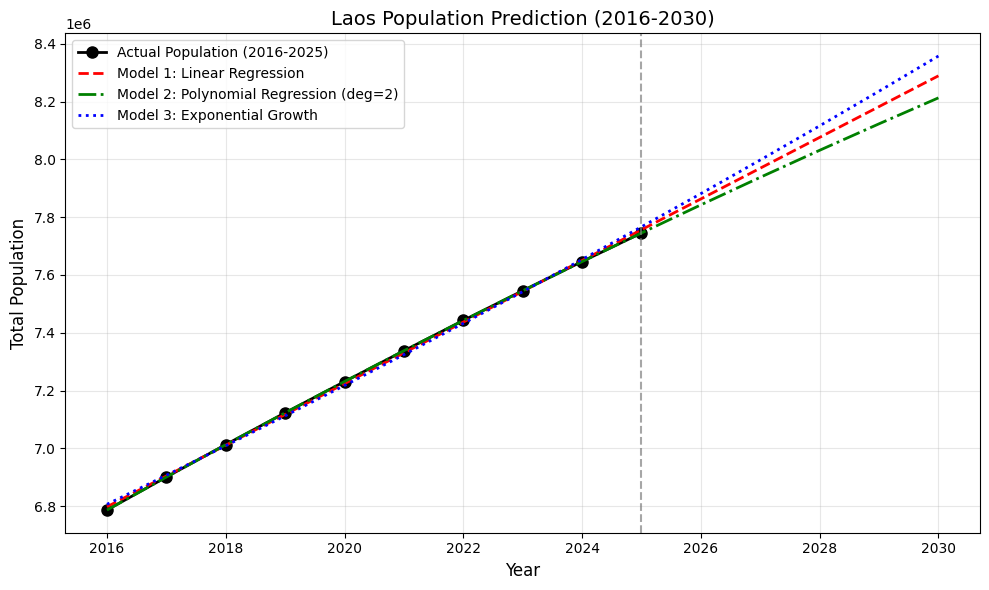

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Load Data
df = pd.read_csv('data/dataDistrict.csv')
years = [str(y) for y in range(2016, 2026)]
yearly_pop = df[years].sum()

X = np.array(range(2016, 2026)).reshape(-1, 1)
y = yearly_pop.values
X_future = np.array(range(2026, 2031)).reshape(-1, 1)
X_all = np.array(range(2016, 2031)).reshape(-1, 1)

# Model 1: Linear Regression
lr = LinearRegression()
lr.fit(X, y)
y_pred_lr_train = lr.predict(X)
y_pred_lr_future = lr.predict(X_future)
y_pred_lr_all = lr.predict(X_all)

# Model 2: Polynomial Regression (Degree 2)
poly = PolynomialFeatures(degree=2)
X_poly = poly.fit_transform(X)
X_all_poly = poly.transform(X_all)
pr = LinearRegression()
pr.fit(X_poly, y)
y_pred_pr_train = pr.predict(X_poly)
y_pred_pr_future = pr.predict(poly.transform(X_future))
y_pred_pr_all = pr.predict(X_all_poly)

# Model 3: Exponential Growth (Log-Linear Regression)
# ແທນທີ່ Exponential Smoothing ດ້ວຍ Log-Linear ທີ່ໃຊ້ພຽງແຕ່ numpy & sklearn
log_y = np.log(y)
exp_model = LinearRegression()
exp_model.fit(X, log_y)
y_pred_exp_train = np.exp(exp_model.predict(X))
y_pred_exp_future = np.exp(exp_model.predict(X_future))
y_pred_exp_all = np.exp(exp_model.predict(X_all))

# Calculate Metrics
def calc_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    return mae, rmse, mape

metrics_lr = calc_metrics(y, y_pred_lr_train)
metrics_pr = calc_metrics(y, y_pred_pr_train)
metrics_exp = calc_metrics(y, y_pred_exp_train)

print(f"Linear: MAE={metrics_lr[0]:.2f}, RMSE={metrics_lr[1]:.2f}, MAPE={metrics_lr[2]:.4f}%")
print(f"Polynomial: MAE={metrics_pr[0]:.2f}, RMSE={metrics_pr[1]:.2f}, MAPE={metrics_pr[2]:.4f}%")
print(f"Exponential: MAE={metrics_exp[0]:.2f}, RMSE={metrics_exp[1]:.2f}, MAPE={metrics_exp[2]:.4f}%")
print(f"Predictions 2026-2030 (Linear): {np.round(y_pred_lr_future).astype(int)}")
print(f"Predictions 2026-2030 (Poly): {np.round(y_pred_pr_future).astype(int)}")
print(f"Predictions 2026-2030 (Exp): {np.round(y_pred_exp_future).astype(int)}")

# Create Chart
plt.figure(figsize=(10, 6))
plt.plot(range(2016, 2026), y, 'ko-', label='Actual Population (2016-2025)', linewidth=2, markersize=8)
plt.plot(range(2016, 2031), y_pred_lr_all, 'r--', label='Model 1: Linear Regression', linewidth=2)
plt.plot(range(2016, 2031), y_pred_pr_all, 'g-.', label='Model 2: Polynomial Regression (deg=2)', linewidth=2)
plt.plot(range(2016, 2031), y_pred_exp_all, 'b:', label='Model 3: Exponential Growth', linewidth=2)
plt.axvline(x=2025, color='gray', linestyle='--', alpha=0.7)
plt.title('Laos Population Prediction (2016-2030)', fontsize=14)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Total Population', fontsize=12)
plt.legend(fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('population_forecast_fixed.png')
plt.show()

In [2]:
df.head(5)

,ouID,ouName,deID,deName,cocID,cocName,cocCode,sexID,sexName,sexCode,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,J41dVMJoZF7,0101 Chanthabouli,D8Q6nNeQ7i3,Population,gD6R57qNqUQ,0 year,0,qrdVdBdFbzw,Male,M,723,727,730,731,731,727,722,716,706,696
1,J41dVMJoZF7,0101 Chanthabouli,D8Q6nNeQ7i3,Population,gD6R57qNqUQ,0 year,0,P7HGqoogYdR,Female,F,694,698,701,702,702,700,695,688,679,669
2,J41dVMJoZF7,0101 Chanthabouli,D8Q6nNeQ7i3,Population,lL13Etbecym,1 year,1,qrdVdBdFbzw,Male,M,538,719,723,727,729,728,725,719,712,702
3,J41dVMJoZF7,0101 Chanthabouli,D8Q6nNeQ7i3,Population,lL13Etbecym,1 year,1,P7HGqoogYdR,Female,F,507,687,691,694,695,695,693,688,681,672
4,J41dVMJoZF7,0101 Chanthabouli,D8Q6nNeQ7i3,Population,bGWFD3wbySU,2 years,2,qrdVdBdFbzw,Male,M,537,537,718,723,727,728,727,724,718,711


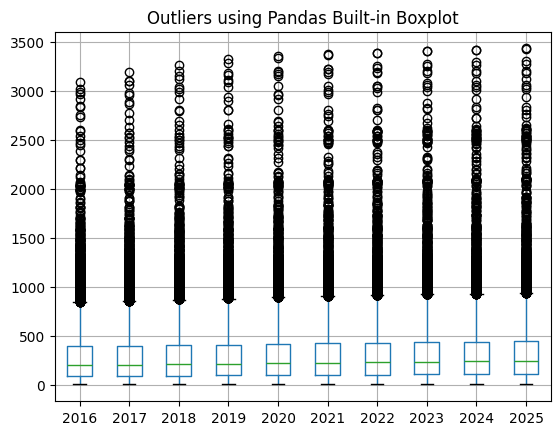

In [3]:
# Plot boxplots for all numerical columns
df.boxplot()

# Or plot just one specific column:
# df.boxplot(column=['Value_A'])

plt.title("Outliers using Pandas Built-in Boxplot")
plt.show()

<h1>ການບັນທຶກເປັນ csv</h1>

In [2]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures

# 1. ໂຫຼດຂໍ້ມູນ (ປ່ຽນຊື່ໄຟລ໌ເປັນ dataDistrict_2.csv ຕາມທີ່ເຈົ້າຕ້ອງການ)
df = pd.read_csv('data/dataDistrict.csv')

# 2. ກຳນົດປີ (ຕົວແປ)
year_cols = [str(y) for y in range(2016, 2026)]
future_years = [str(y) for y in range(2026, 2031)]

X = np.array(range(2016, 2026)).reshape(-1, 1)
X_future = np.array(range(2026, 2031)).reshape(-1, 1)

poly = PolynomialFeatures(degree=2)
X_poly = poly.fit_transform(X)
X_future_poly = poly.transform(X_future)

# ກຽມ List ສຳລັບເກັບຄ່າທຳນາຍ
preds_lr = []
preds_poly = []
preds_exp = []

print("ກຳລັງປະມວນຜົນທຳນາຍແຕ່ລະແຖວ... ກະລຸນາລໍຖ້າບຶດໜຶ່ງ")

# 3. ວົນ Loop ຄິດໄລ່ Model ສຳລັບແຕ່ລະເມືອງ ແລະ ກຸ່ມອາຍຸ (ແຕ່ລະແຖວ)
for index, row in df.iterrows():
    # ດຶງຂໍ້ມູນປະຊາກອນປີ 2016-2025 ຂອງແຖວນັ້ນ
    y = row[year_cols].values.astype(float)
    
    # --- Model 1: Linear Regression ---
    lr = LinearRegression()
    lr.fit(X, y)
    p_lr = lr.predict(X_future)
    
    # --- Model 2: Polynomial Regression (Deg=2) ---
    pr = LinearRegression()
    pr.fit(X_poly, y)
    p_pr = pr.predict(X_future_poly)
    
    # --- Model 3: Exponential Growth ---
    # ປ້ອງກັນ Error ການຄິດໄລ່ Log ກັບຄ່າ 0 ຫຼື ຄ່າລົບ (ປ່ຽນເປັນຄ່ານ້ອຍໆແທນ)
    y_safe = np.where(y <= 0, 0.1, y)
    log_y = np.log(y_safe)
    exp_model = LinearRegression()
    exp_model.fit(X, log_y)
    p_exp = np.exp(exp_model.predict(X_future))
    
    # ເກັບຄ່າທຳນາຍລົງໃນ List
    preds_lr.append(np.round(p_lr).astype(int))
    preds_poly.append(np.round(p_pr).astype(int))
    preds_exp.append(np.round(p_exp).astype(int))

# 4. ສ້າງ DataFrame ສຳລັບຜົນການທຳນາຍຂອງທັງ 3 Models
df_lr = pd.DataFrame(preds_lr, columns=[f"{y}_Linear" for y in future_years])
df_poly = pd.DataFrame(preds_poly, columns=[f"{y}_Poly" for y in future_years])
df_exp = pd.DataFrame(preds_exp, columns=[f"{y}_Exp" for y in future_years])

# 5. ນຳເອົາຜົນທຳນາຍທັງໝົດ ມາຕໍ່ທ້າຍຕາຕະລາງເດີມ (Original Data)
df_final = pd.concat([df, df_lr, df_poly, df_exp], axis=1)

# ເຊັກຄວາມຖືກຕ້ອງ: ປ້ອງກັນບໍ່ໃຫ້ຕົວເລກທຳນາຍອອກມາຕິດລົບ (ຖ້າມີໃຫ້ປ່ຽນເປັນ 0)
for col in df_final.columns:
    if "Linear" in col or "Poly" in col or "Exp" in col:
        df_final[col] = df_final[col].clip(lower=0)

# 6. ບັນທຶກເປັນໄຟລ໌ CSV ອັນດຽວທີ່ສົມບູນ
output_file = 'dataDistrict_Predicted_All_Models.csv'
# # output_file = 'dataDistrict_Predicted_All_Models.html'

df_final.to_csv(output_file, index=False)
# # df_final.to_html(output_file, index=False)

print(f"✅ ສຳເລັດ! ບັນທຶກຂໍ້ມູນທັງໝົດລົງໃນໄຟລ໌: {output_file} ຮຽບຮ້ອຍແລ້ວ.")

ກຳລັງປະມວນຜົນທຳນາຍແຕ່ລະແຖວ... ກະລຸນາລໍຖ້າບຶດໜຶ່ງ
✅ ສຳເລັດ! ບັນທຶກຂໍ້ມູນທັງໝົດລົງໃນໄຟລ໌: dataDistrict_Predicted_All_Models.csv ຮຽບຮ້ອຍແລ້ວ.


<hr><h1>Save to html</h1>

In [5]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures

# 1. ໂຫຼດຂໍ້ມູນ (ປ່ຽນຊື່ໄຟລ໌ເປັນ dataDistrict.csv ຕາມທີ່ເຈົ້າຕ້ອງການ)
df = pd.read_csv('data/dataDistrict.csv')

# 2. ກຳນົດປີ (ຕົວແປ)
year_cols = [str(y) for y in range(2016, 2026)]
future_years = [str(y) for y in range(2026, 2031)]

X = np.array(range(2016, 2026)).reshape(-1, 1)
X_future = np.array(range(2026, 2031)).reshape(-1, 1)

poly = PolynomialFeatures(degree=2)
X_poly = poly.fit_transform(X)
X_future_poly = poly.transform(X_future)

# ກຽມ List ສຳລັບເກັບຄ່າທຳນາຍ
preds_lr = []
preds_poly = []
preds_exp = []

print("ກຳລັງປະມວນຜົນທຳນາຍແຕ່ລະແຖວ... ກະລຸນາລໍຖ້າບຶດໜຶ່ງ")

# 3. ວົນ Loop ຄິດໄລ່ Model ສຳລັບແຕ່ລະເມືອງ ແລະ ກຸ່ມອາຍຸ (ແຕ່ລະແຖວ)
for index, row in df.iterrows():
    # ດຶງຂໍ້ມູນປະຊາກອນປີ 2016-2025 ຂອງແຖວນັ້ນ
    y = row[year_cols].values.astype(float)
    
    # --- Model 1: Linear Regression ---
    lr = LinearRegression()
    lr.fit(X, y)
    p_lr = lr.predict(X_future)
    
    # --- Model 2: Polynomial Regression (Deg=2) ---
    pr = LinearRegression()
    pr.fit(X_poly, y)
    p_pr = pr.predict(X_future_poly)
    
    # --- Model 3: Exponential Growth ---
    # ປ້ອງກັນ Error ການຄິດໄລ່ Log ກັບຄ່າ 0 ຫຼື ຄ່າລົບ (ປ່ຽນເປັນຄ່ານ້ອຍໆແທນ)
    y_safe = np.where(y <= 0, 0.1, y)
    log_y = np.log(y_safe)
    exp_model = LinearRegression()
    exp_model.fit(X, log_y)
    p_exp = np.exp(exp_model.predict(X_future))
    
    # ເກັບຄ່າທຳນາຍລົງໃນ List
    preds_lr.append(np.round(p_lr).astype(int))
    preds_poly.append(np.round(p_pr).astype(int))
    preds_exp.append(np.round(p_exp).astype(int))

# 4. ສ້າງ DataFrame ສຳລັບຜົນການທຳນາຍຂອງທັງ 3 Models
df_lr = pd.DataFrame(preds_lr, columns=[f"{y}_Linear" for y in future_years])
df_poly = pd.DataFrame(preds_poly, columns=[f"{y}_Poly" for y in future_years])
df_exp = pd.DataFrame(preds_exp, columns=[f"{y}_Exp" for y in future_years])

# 5. ນຳເອົາຜົນທຳນາຍທັງໝົດ ມາຕໍ່ທ້າຍຕາຕະລາງເດີມ (Original Data)
df_final = pd.concat([df, df_lr, df_poly, df_exp], axis=1)

# ເຊັກຄວາມຖືກຕ້ອງ: ປ້ອງກັນບໍ່ໃຫ້ຕົວເລກທຳນາຍອອກມາຕິດລົບ (ຖ້າມີໃຫ້ປ່ຽນເປັນ 0)
for col in df_final.columns:
    if "Linear" in col or "Poly" in col or "Exp" in col:
        df_final[col] = df_final[col].clip(lower=0)


# **************** make to html ***************

# 1. Define the columns to remove
cols_to_drop = [
    '2026_Linear', '2027_Linear', '2028_Linear', '2029_Linear', '2030_Linear',
    '2026_Exp', '2027_Exp', '2028_Exp', '2029_Exp', '2030_Exp'
]

# 2. Drop the columns
df_final = df_final.drop(columns=cols_to_drop)

# 3. Add the row-wise 'Total' column at the end
year_columns = [
    '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025',
    '2026_Poly', '2027_Poly', '2028_Poly', '2029_Poly', '2030_Poly'
]
df_final['Total'] = df_final[year_columns].sum(axis=1)


# ---------------------------------------------------------
# 4. NEW: Add a "Grand Total" row at the bottom of the table
# ---------------------------------------------------------

# Create an empty dictionary to structure the bottom row
bottom_total_row = {col: '' for col in df_final.columns}

# Put the label 'Grand Total' in the very first column (e.g., your ouName column)
bottom_total_row[df_final.columns[0]] = 'Grand Total'

# Calculate the sums for all the year columns and the new Total column
numeric_cols_to_sum = year_columns + ['Total']
for col in numeric_cols_to_sum:
    bottom_total_row[col] = df_final[col].sum()

# Append this new row to the dataframe
df_final = pd.concat([df_final, pd.DataFrame([bottom_total_row])], ignore_index=True)
# ---------------------------------------------------------


# 5. Save to HTML
output_file = 'dataDistrict_Predicted_All_Models.html'
df_final.to_html(output_file, index=False)

print(f"✅ ສຳເລັດ! ບັນທຶກຂໍ້ມູນທັງໝົດລົງໃນໄຟລ໌: {output_file} ຮຽບຮ້ອຍແລ້ວ.")

ກຳລັງປະມວນຜົນທຳນາຍແຕ່ລະແຖວ... ກະລຸນາລໍຖ້າບຶດໜຶ່ງ
✅ ສຳເລັດ! ບັນທຶກຂໍ້ມູນທັງໝົດລົງໃນໄຟລ໌: dataDistrict_Predicted_All_Models.html ຮຽບຮ້ອຍແລ້ວ.


<hr>


=== Model Performance (2016-2025) ===
Linear:      R² = 0.9995 | Accuracy = 99.9179% | MAPE = 0.0821% | RMSE = 6760.6901
Polynomial:  R² = 1.0000 | Accuracy = 99.9975% | MAPE = 0.0025% | RMSE = 202.3716
Exponential: R² = 0.9983 | Accuracy = 99.8491% | MAPE = 0.1509% | RMSE = 12451.0152

=== Predictions (2026-2030) ===
Linear:      [7863120 7969638 8076155 8182673 8289191]
Linear_All:      [6797942 6904460 7010978 7117496 7224013 7330531 7437049 7543567 7650084
 7756602 7863120 7969638 8076155 8182673 8289191]
Linear_All_Train:      [6797942 6904460 7010978 7117496 7224013 7330531 7437049 7543567 7650084
 7756602]
Polynomial:  [7842660 7938018 8031516 8123154 8212931]
Exponential: [7881541 7997971 8116121 8236016 8357682]



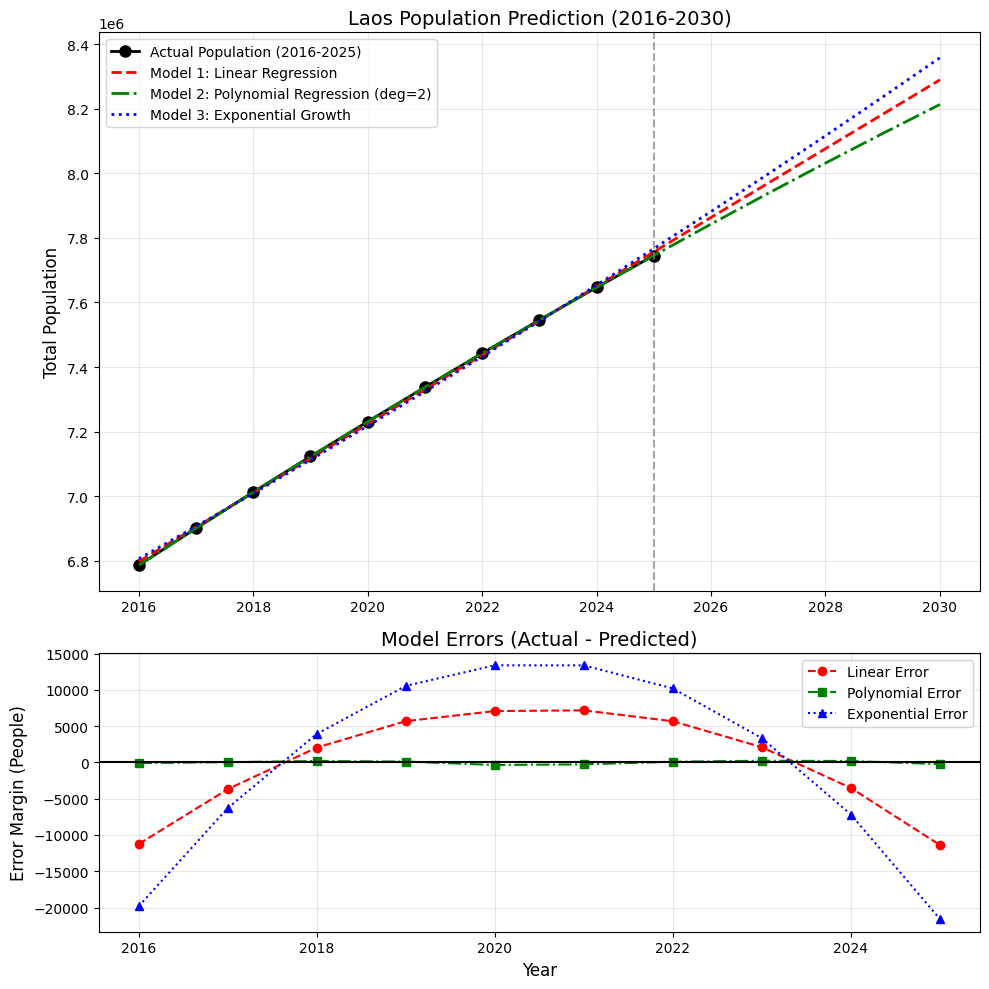

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ==========================================
# 1. Load Data
# ==========================================
df = pd.read_csv('data/dataDistrict.csv')
years = [str(y) for y in range(2016, 2026)]
yearly_pop = df[years].sum()

X = np.array(range(2016, 2026)).reshape(-1, 1)
y = yearly_pop.values
X_future = np.array(range(2026, 2031)).reshape(-1, 1)
X_all = np.array(range(2016, 2031)).reshape(-1, 1)

# ==========================================
# 2. Build Models
# ==========================================

# Model 1: Linear Regression
lr = LinearRegression()
lr.fit(X, y)
y_pred_lr_train = lr.predict(X)
y_pred_lr_future = lr.predict(X_future)
y_pred_lr_all = lr.predict(X_all)

# Model 2: Polynomial Regression (Degree 2)
poly = PolynomialFeatures(degree=2)
X_poly = poly.fit_transform(X)
X_all_poly = poly.transform(X_all)
pr = LinearRegression()
pr.fit(X_poly, y)
y_pred_pr_train = pr.predict(X_poly)
y_pred_pr_future = pr.predict(poly.transform(X_future))
y_pred_pr_all = pr.predict(X_all_poly)

# Model 3: Exponential Growth (Log-Linear Regression)
log_y = np.log(y)
exp_model = LinearRegression()
exp_model.fit(X, log_y)
y_pred_exp_train = np.exp(exp_model.predict(X))
y_pred_exp_future = np.exp(exp_model.predict(X_future))
y_pred_exp_all = np.exp(exp_model.predict(X_all))

# ==========================================
# 3. Calculate Metrics (Accuracy & Errors)
# ==========================================
def calc_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    
    # R-squared Score (ຍິ່ງໃກ້ 1.0 ຍິ່ງດີ)
    r2 = r2_score(y_true, y_pred)
    
    # ຄິດໄລ່ Accuracy ຈາກ MAPE
    accuracy = 100 - mape 
    
    return mae, rmse, mape, r2, accuracy

metrics_lr = calc_metrics(y, y_pred_lr_train)
metrics_pr = calc_metrics(y, y_pred_pr_train)
metrics_exp = calc_metrics(y, y_pred_exp_train)

print("\n=== Model Performance (2016-2025) ===")
print(f"Linear:      R² = {metrics_lr[3]:.4f} | Accuracy = {metrics_lr[4]:.4f}% | MAPE = {metrics_lr[2]:.4f}% | RMSE = {metrics_lr[1]:.4f}")
print(f"Polynomial:  R² = {metrics_pr[3]:.4f} | Accuracy = {metrics_pr[4]:.4f}% | MAPE = {metrics_pr[2]:.4f}% | RMSE = {metrics_pr[1]:.4f}")
print(f"Exponential: R² = {metrics_exp[3]:.4f} | Accuracy = {metrics_exp[4]:.4f}% | MAPE = {metrics_exp[2]:.4f}% | RMSE = {metrics_exp[1]:.4f}")
print("=====================================\n")

print("=== Predictions (2026-2030) ===")
print(f"Linear:      {np.round(y_pred_lr_future).astype(int)}")

print(f"Linear_All:      {np.round(y_pred_lr_all).astype(int)}")
print(f"Linear_All_Train:      {np.round(y_pred_lr_train).astype(int)}")


print(f"Polynomial:  {np.round(y_pred_pr_future).astype(int)}")
print(f"Exponential: {np.round(y_pred_exp_future).astype(int)}")
print("===============================\n")

# ==========================================
# 4. Create Charts (Prediction + Residuals)
# ==========================================
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 10), gridspec_kw={'height_ratios': [2, 1]})

# --- Chart 1: Population Prediction ---
ax1.plot(range(2016, 2026), y, 'ko-', label='Actual Population (2016-2025)', linewidth=2, markersize=8)
ax1.plot(range(2016, 2031), y_pred_lr_all, 'r--', label='Model 1: Linear Regression', linewidth=2)
ax1.plot(range(2016, 2031), y_pred_pr_all, 'g-.', label='Model 2: Polynomial Regression (deg=2)', linewidth=2)
ax1.plot(range(2016, 2031), y_pred_exp_all, 'b:', label='Model 3: Exponential Growth', linewidth=2)

ax1.axvline(x=2025, color='gray', linestyle='--', alpha=0.7)
ax1.set_title('Laos Population Prediction (2016-2030)', fontsize=14)
ax1.set_ylabel('Total Population', fontsize=12)
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3)

# --- Chart 2: Residuals / Error Margin ---
ax2.plot(range(2016, 2026), y - y_pred_lr_train, 'r--o', label='Linear Error')
ax2.plot(range(2016, 2026), y - y_pred_pr_train, 'g-.s', label='Polynomial Error')
ax2.plot(range(2016, 2026), y - y_pred_exp_train, 'b:^', label='Exponential Error')

ax2.axhline(y=0, color='black', linestyle='-', linewidth=1.5) # ເສັ້ນ 0 ຄືທຳນາຍຖືກ 100%
ax2.set_title('Model Errors (Actual - Predicted)', fontsize=14)
ax2.set_xlabel('Year', fontsize=12)
ax2.set_ylabel('Error Margin (People)', fontsize=12)
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('population_forecast_complete.png', dpi=300)
plt.show()